# HASTS206 Assignment 2: Part 1(c): Abridged life table

**All data are hypothetical (synthetic).** Run from the repository root. The first code cell runs the previous part (`part2_structure_rates.ipynb`) so that all earlier variables exist.

In [ ]:
%run part2_structure_rates.ipynb

### 1(c) Abridged life table
Construction (pooled sexes, radix l0 = 100,000):
- m_x = deaths / person-years
- q_x = n m_x / (1 + (n - a_x) m_x), for the closed intervals; q_85+ = 1
- l_(x+n) = l_x (1 - q_x); d_x = l_x q_x
- L_x = n l_(x+n) + a_x d_x for closed intervals; L_85+ = l_85 / m_85+
- T_x = sum of L from x upward; e_x = T_x / l_x

In [12]:
# What this cell does: Builds the abridged life table step by step: central death rates m(x), then
# q(x), l(x), d(x), L(x), T(x) and e(x), starting from a radix of 100,000.
lt = life_in.copy()
lt['n'] = lt.interval_years
lt['mx'] = lt.deaths / lt.person_years
N = len(lt); qx = np.zeros(N); lx = np.zeros(N); dx = np.zeros(N); Lx = np.zeros(N)
for i in range(N):
    if i < N - 1:
        qx[i] = lt.n[i] * lt.mx[i] / (1 + (lt.n[i] - lt.ax[i]) * lt.mx[i])
    else:
        qx[i] = 1.0
lx[0] = 100000
for i in range(N):
    dx[i] = lx[i] * qx[i]
    if i < N - 1: lx[i + 1] = lx[i] - dx[i]
for i in range(N):
    Lx[i] = lt.n[i] * lx[i + 1] + lt.ax[i] * dx[i] if i < N - 1 else lx[i] / lt.mx[i]
Tx = np.cumsum(Lx[::-1])[::-1]
lt['qx'], lt['lx'], lt['dx'], lt['Lx'], lt['Tx'] = qx, lx, dx, Lx, Tx
lt['ex'] = lt.Tx / lt.lx
lt['age'] = lt.age_start.map(AGE_LAB)
life_table = lt[['age', 'age_start', 'person_years', 'deaths', 'mx', 'qx', 'lx', 'dx', 'Lx', 'Tx', 'ex']]
print(life_table.round({'mx': 5, 'qx': 5, 'lx': 1, 'dx': 1, 'Lx': 1, 'Tx': 1, 'ex': 2}).to_string(index=False))

  age  age_start  person_years  deaths     mx     qx          lx          dx           Lx             Tx      ex
  0-4          0        125000    1000 0.0080 0.0388     100,000       3,882 485,248.4000 7,310,912.7000 73.1100
  5-9          5        120000     108 0.0009 0.0045      96,118    431.6000 479,511.2000 6,825,664.3000 71.0100
10-14         10        115000      69 0.0006 0.0030 95,686.5000    286.6000 477,715.7000 6,346,153.1000 66.3200
15-19         15        110000      88 0.0008 0.0040 95,399.8000    380.8000      476,047 5,868,437.4000 61.5100
20-24         20        105000     116 0.0011 0.0055      95,019    523.4000 473,786.4000 5,392,390.4000 56.7500
25-29         25        100000     150 0.0015 0.0075 94,495.6000    706.1000 470,712.6000      4,918,604 52.0500
30-34         30         95000     190 0.0020 0.0100 93,789.5000    933.2000 466,614.4000 4,447,891.4000 47.4200
35-39         35         90000     243 0.0027 0.0134 92,856.3000  1,245.2000 461,168.4000      3

**Notes: how the life table was built.** We start with m(x) = deaths / person-years. Then each q(x) = n m(x) / (1 + (n - a(x)) m(x)), using the supplied interval widths and a(x) (1.2 for ages 0-4, because deaths in infancy happen early, and 2.5 for the others). The last group has q = 1, so every survivor dies eventually, and L(85+) = l(85) / m(85+). Death rates climb quickly with age, from about 0.0006 at ages 10-14 to 0.141 at 85+. The 0-4 band is high (0.0080) because of infant and child deaths.

e0  = 73.11 years      e65 = 18.10 years
Survivors to age 65: l65 = 76,207 of 100,000 (76.2%)

Check 1: sum of d_x = 100,000.0000  (must equal radix 100,000)
Check 2: T_0 - sum(L_x) = 0.000000  (must be 0)
Check 3: for ages 5-84 (a=2.5), max |L_x - 2.5(l_x + l_x+5)| = 5.82e-11  (L equals the trapezium rule when a=n/2)
Check 4: e_85+ = 7.092 = 1/m_85+ = 7.092


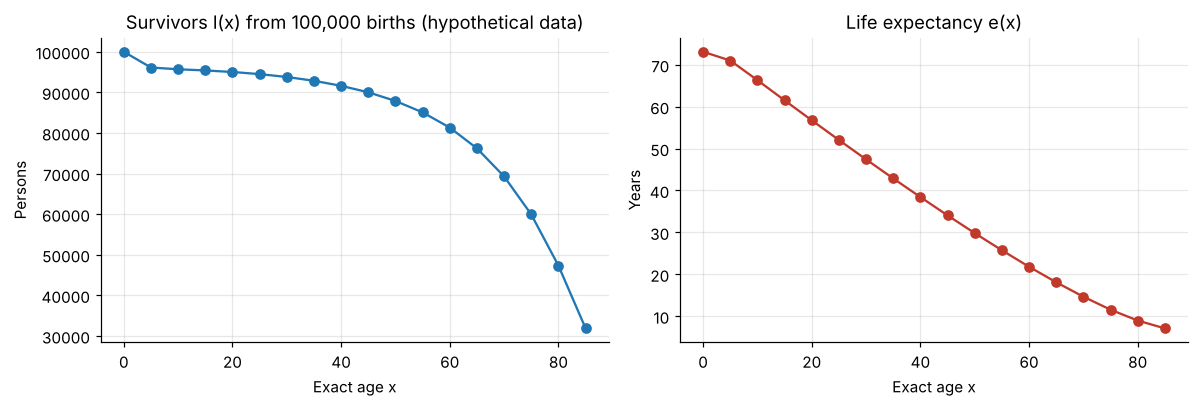

In [13]:
# What this cell does: Reads off life expectancy at birth and at age 65, then runs four numerical
# checks on the table.
e0, e65 = lt.ex[0], lt.ex[lt.age_start == 65].iloc[0]
l65 = lt.lx[lt.age_start == 65].iloc[0]
chk1 = dx.sum()
chk2 = Tx[0] - (Lx.sum())
trap = [abs(Lx[i] - 2.5 * (lx[i] + lx[i + 1])) for i in range(1, N - 1)]
print(f'e0  = {e0:.2f} years      e65 = {e65:.2f} years')
print(f'Survivors to age 65: l65 = {l65:,.0f} of 100,000 ({l65/1000:.1f}%)')
print(f'\nCheck 1: sum of d_x = {chk1:,.4f}  (must equal radix 100,000)')
print(f'Check 2: T_0 - sum(L_x) = {chk2:.6f}  (must be 0)')
print(f'Check 3: for ages 5-84 (a=2.5), max |L_x - 2.5(l_x + l_x+5)| = {max(trap):.2e}  (L equals the trapezium rule when a=n/2)')
print(f'Check 4: e_85+ = {lt.ex.iloc[-1]:.3f} = 1/m_85+ = {1/lt.mx.iloc[-1]:.3f}')
KEY['lt'] = dict(e0=e0, e65=e65, l65=l65, q0=qx[0], q65=float(lt.qx[lt.age_start==65].iloc[0]), e85=float(lt.ex.iloc[-1]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(lt.age_start, lt.lx, marker='o'); ax[0].set_title(f'Survivors l(x) from 100,000 births {HYP}'); ax[0].set_xlabel('Exact age x'); ax[0].set_ylabel('Persons')
ax[1].plot(lt.age_start, lt.ex, marker='o', color='#c0392b'); ax[1].set_title('Life expectancy e(x)'); ax[1].set_xlabel('Exact age x'); ax[1].set_ylabel('Years')
fig.tight_layout(); fig.savefig(FIG / 'life_table.png', dpi=150)
life_table.to_csv(OUT / 'life_table.csv', index=False)

**Notes: what the life table says.**
- **Life expectancy at birth is 73.11 years.** A newborn would live about 73.1 years on average if the death rates in this schedule stayed the same for a whole lifetime. It is a period measure for pooled sexes, not a forecast.
- **Life expectancy at 65 is 18.10 years.** People who reach 65 can expect about 18.1 more years, so they live to about 83.1 on average, which is higher than e0. That is because e0 includes the people who die as babies and in middle age, and those who reach 65 have already got through those risks. Only 76.2% of babies survive to 65.
- **Checks:** the d(x) column adds to exactly 100,000, T(0) equals the sum of L(x), L(x) matches the trapezium rule wherever a = 2.5, and e(85+) equals 1/m(85+) (7.092 years). All of them hold to machine precision.